In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data.csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0           4
1  2018-01-04      1  address_0    product_1           4
2  2018-01-04      1  address_0    product_2           5
3  2018-01-04      1  address_0    product_3          10
4  2018-01-04      1  address_0    product_4           2


In [3]:
df.shape

(301355, 5)

Проверяем формат столбцов

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 301355 entries, 0 to 301354
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   Дата          301355 non-null  str  
 1   Склад         301355 non-null  int64
 2   Контрагент    301355 non-null  str  
 3   Номенклатура  301355 non-null  str  
 4   Количество    301355 non-null  int64
dtypes: int64(2), str(3)
memory usage: 20.0 MB


Сразу переведем столбец "Дата" в правильный формат

In [5]:
df['Дата'] = pd.to_datetime(df['Дата'])
df.dtypes

Дата            datetime64[us]
Склад                    int64
Контрагент                 str
Номенклатура               str
Количество               int64
dtype: object

Сгруппируйте данные по дате, посчитайте количество продаж

In [6]:
grouped_df = df.groupby('Дата', as_index=False)['Количество'].sum()
grouped_df = grouped_df.rename(columns={'Количество': 'Количество продаж'})

Вывести несколько первых строк сгруппированных данных

In [7]:
grouped_df.head()

,Дата,Количество продаж
0,2018-01-04,3734
1,2018-01-05,3643
2,2018-01-06,3193
3,2018-01-07,3298
4,2018-01-09,4055


Нарисуйте график продаж у `grouped_df`

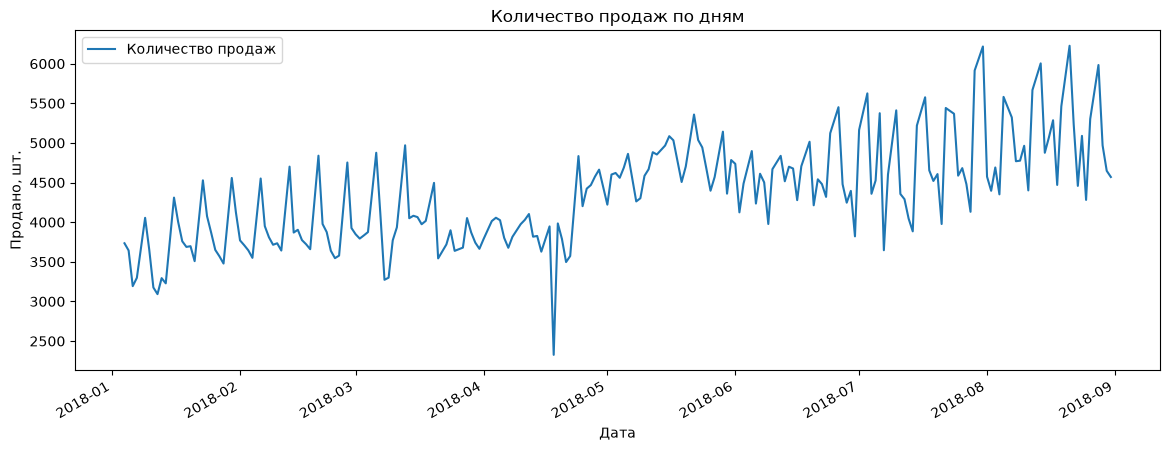

count     205.0
mean     4339.0
std       648.0
min      2326.0
25%      3821.0
50%      4319.0
75%      4702.0
max      6226.0
Name: Количество продаж, dtype: float64

Продажи по месяцам:
Дата
2018-01-01     89183
2018-02-01     93839
2018-03-01    102064
2018-04-01     98833
2018-05-01    127440
2018-06-01    118034
2018-07-01    124654
2018-08-01    135420
Freq: MS, Name: Количество продаж, dtype: int64

Средние продажи по дням недели (0 = понедельник):
Дата
1    4911.0
2    4269.0
3    4263.0
4    4228.0
5    3978.0
6    4388.0
Name: Количество продаж, dtype: float64

Самые слабые дни:
         Дата  Количество продаж
88 2018-04-18               2326
7  2018-01-12               3092
6  2018-01-11               3176


In [8]:
ax = grouped_df.plot(x='Дата', y='Количество продаж', figsize=(14, 5), title='Количество продаж по дням')
ax.set_ylabel('Продано, шт.')
plt.show()

# вспомогательные цифры для описания графика
print(grouped_df['Количество продаж'].describe().round(0))
print('\nПродажи по месяцам:')
print(grouped_df.set_index('Дата')['Количество продаж'].resample('MS').sum())
print('\nСредние продажи по дням недели (0 = понедельник):')
print(grouped_df.groupby(grouped_df['Дата'].dt.dayofweek)['Количество продаж'].mean().round(0))
print('\nСамые слабые дни:')
print(grouped_df.nsmallest(3, 'Количество продаж'))

Опишите что вы видите на графике. Ваша задача - максимально описать график

**Описание графика**

- **Период**: 4 января – 31 августа 2018 года, 205 дней с продажами. Понедельников в данных нет: по понедельникам продаж нет (выходной), поэтому на графике регулярные «разрывы».
- **Уровень**: в среднем ≈4 340 шт. в день, медиана 4 319. Обычный диапазон 3 800–4 700 (между 25-м и 75-м процентилями), минимум 2 326, максимум 6 226.
- **Тренд**: восходящий. Январь ≈89 тыс. шт. за месяц, август ≈135 тыс. (+52%). Ступенчатый скачок уровня сразу после 18 апреля: дневные продажи переходят с ≈3 800 на ≈4 600 и выше, поэтому май намного сильнее апреля (127 тыс. против 99 тыс.); в июне небольшой спад (118 тыс.), затем рост в июле–августе до максимума периода.
- **Недельная сезонность**: график «пилообразный», продажи колеблются внутри недели. Сильнее всего вторник (в среднем ≈4 910 шт.), минимум в субботу (≈3 980), в воскресенье подъём (≈4 390); среда–пятница ≈4 230–4 270.
- **Аномалии**: резкий провал 18 апреля 2018 (2 326 шт., почти вдвое ниже нормы); вероятно, сбой учёта или неполный день. Слабые дни в начале января (праздники, 3 100–3 200 шт.). Пики свыше 6 000 шт. в конце июля и в августе.
- **Волатильность**: стандартное отклонение ≈650 шт. в день (≈15% от среднего). Самые сильные колебания в июле (коэффициент вариации 14%), самые ровные в мае–июне (6–8%).

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [9]:
# выброс ищем по межквартильному размаху (IQR), максимальный выброс - строка с наибольшим 'Количество'
q1, q3 = df['Количество'].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
outliers = df[df['Количество'] > upper]
print(f'Граница выброса: > {upper}, строк-выбросов: {len(outliers)}')
df.loc[[df['Количество'].idxmax()]]

Граница выброса: > 8.5, строк-выбросов: 13140


,Дата,Склад,Контрагент,Номенклатура,Количество
218822,2018-06-28,1,address_208,product_0,200


Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [10]:
mask = (
    (df['Склад'] == 3)
    & (df['Дата'].dt.dayofweek == 2)            # среда
    & (df['Дата'].dt.month.isin([6, 7, 8]))    # июнь, июль, август
)
top = df[mask].groupby('Номенклатура')['Количество'].sum().sort_values(ascending=False)
print(top.head())
print('Топовый товар:', top.index[0])

Номенклатура
product_1    2267
product_2    2060
product_0    1324
product_3     914
product_6     650
Name: Количество, dtype: int64
Топовый товар: product_1


Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

        Дата     T
0 2018-01-01  -9.5
1 2018-01-02  -9.5
2 2018-01-03 -11.5
3 2018-01-04 -14.1
4 2018-01-05 -16.9
дней без температуры: 0


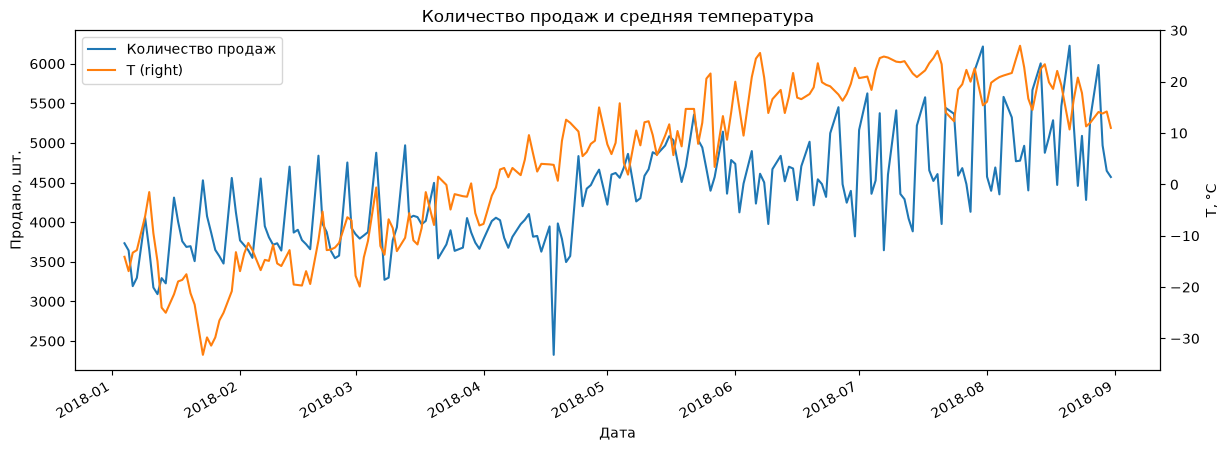

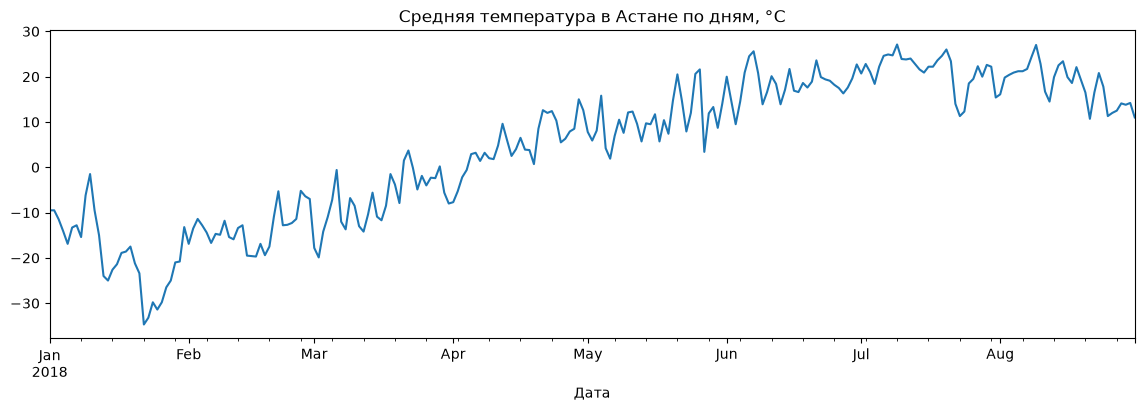

Корреляция продаж и температуры: 0.6


In [11]:
# Источник: rp5.ru, архив погоды Астаны (метеостанция 35188), 01.01.2018 - 31.08.2018,
# формат CSV, кодировка UTF-8. Файл: weather_astana.csv (распакован из .gz)
weather = pd.read_csv('weather_astana.csv', sep=';', comment='#', index_col=False, encoding='utf-8')
time_col = weather.columns[0]  # 'Местное время в Астане' - дата и время наблюдения (каждые 3 часа)
weather['Дата'] = pd.to_datetime(weather[time_col], format='%d.%m.%Y %H:%M').dt.normalize()
weather['T'] = pd.to_numeric(weather['T'], errors='coerce')

temp = weather.groupby('Дата', as_index=False)['T'].mean()  # средняя температура за день
temp['T'] = temp['T'].round(1)
print(temp.head())

merged = grouped_df.merge(temp, on='Дата', how='left')
print('дней без температуры:', merged['T'].isna().sum())

ax = merged.plot(x='Дата', y=['Количество продаж', 'T'], secondary_y='T', figsize=(14, 5),
                 title='Количество продаж и средняя температура')
ax.set_ylabel('Продано, шт.')
ax.right_ax.set_ylabel('T, °C')
plt.show()

temp.plot(x='Дата', y='T', figsize=(14, 4), title='Средняя температура в Астане по дням, °C', legend=False)
plt.show()

print('Корреляция продаж и температуры:', round(merged['Количество продаж'].corr(merged['T']), 2))

**Вывод по погоде**

- Температура в Астане за период растёт от −15…−20 °C зимой (минимум ≈−35 °C в конце января) до +20…+25 °C летом; весной (апрель–май) быстрый переход через 0 °C.
- Продажи растут вместе с температурой: коэффициент корреляции ≈0,6 (умеренная положительная связь). Скачок продаж в мае совпадает с устойчивым потеплением.
- Корреляция не доказывает причинность: на продажи влияют и общий тренд роста бизнеса, и день недели. Чтобы отделить эффект погоды, нужна модель с трендом и днём недели.